# Execution Time Visualization

Plots cumulative execution time per iteration for each PSO configuration.

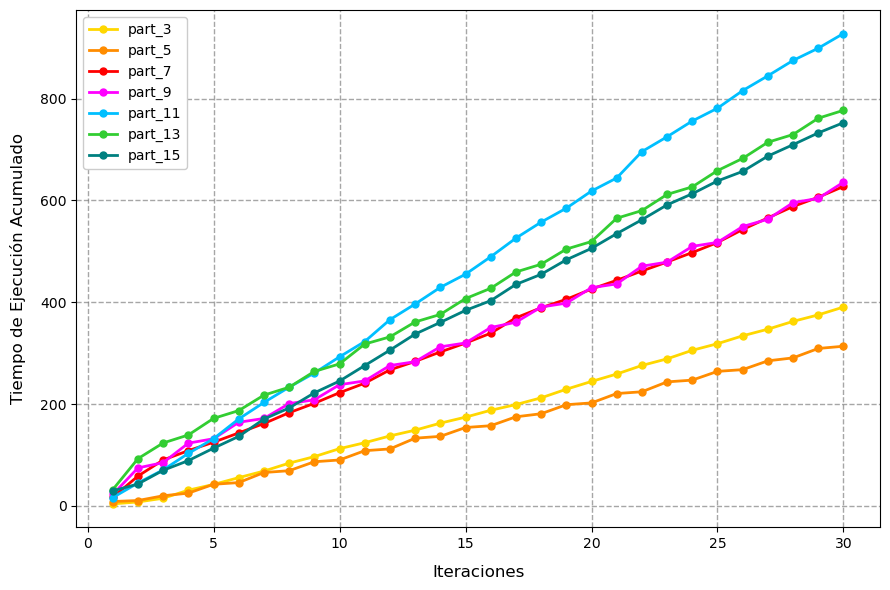

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../results/w_evol_mut_nospeedlimit/w_evol_mut_nospeedlimit.csv', sep=',')


def clean_time(value):
    if pd.isna(value):
        return 0.0
    val_str = str(value)
    last_dot_idx = val_str.rfind('.')
    if last_dot_idx == -1:
        # no decimal point
        return float(val_str.replace(',', '.'))  # handle comma as decimal separator
    # split at last dot
    integer_part = val_str[:last_dot_idx].replace('.', '')  # strip thousands separators
    decimal_part = val_str[last_dot_idx + 1:]
    clean_val = integer_part + '.' + decimal_part
    return float(clean_val)


df['TiempoIter'] = df['TiempoIter'].apply(clean_time)
df['cumulative_time'] = df.groupby('Run')['TiempoIter'].cumsum()

# Filter by run
part_3  = df[df['Run'] == 1]
part_5  = df[df['Run'] == 2]
part_7  = df[df['Run'] == 3]
part_9  = df[df['Run'] == 4]
part_11 = df[df['Run'] == 5]
part_13 = df[df['Run'] == 6]
part_15 = df[df['Run'] == 7]

plt.figure(figsize=(9, 6), dpi=100)

plt.plot(part_3['Iteracion'],  part_3['cumulative_time'],  color='gold',       marker='o', markersize=5, linewidth=2, label='part_3')
plt.plot(part_5['Iteracion'],  part_5['cumulative_time'],  color='darkorange',  marker='o', markersize=5, linewidth=2, label='part_5')
plt.plot(part_7['Iteracion'],  part_7['cumulative_time'],  color='red',         marker='o', markersize=5, linewidth=2, label='part_7')
plt.plot(part_9['Iteracion'],  part_9['cumulative_time'],  color='magenta',     marker='o', markersize=5, linewidth=2, label='part_9')
plt.plot(part_11['Iteracion'], part_11['cumulative_time'], color='deepskyblue', marker='o', markersize=5, linewidth=2, label='part_11')
plt.plot(part_13['Iteracion'], part_13['cumulative_time'], color='limegreen',   marker='o', markersize=5, linewidth=2, label='part_13')
plt.plot(part_15['Iteracion'], part_15['cumulative_time'], color='teal',        marker='o', markersize=5, linewidth=2, label='part_15')

plt.xlabel("Iterations", fontsize=12, labelpad=10)
plt.ylabel("Cumulative Execution Time (s)", fontsize=12, labelpad=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.legend(loc="upper left", fontsize=10, framealpha=1)
plt.grid(color="gray", linestyle="--", linewidth=1, alpha=0.7)
plt.tight_layout()
plt.show()
